<a href="https://colab.research.google.com/github/jesuscarpio5/Analisis-deportivo/blob/main/plantilla_prepartido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mplsoccer statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [2]:
from statsbombpy import sb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch
import textwrap
import warnings
warnings.filterwarnings("ignore")

COMP_ID, SEASON_ID = 11, 27   # La Liga 2015/16
partidos = sb.matches(competition_id=COMP_ID, season_id=SEASON_ID)
partidos["match_date"] = pd.to_datetime(partidos.match_date)

equipos = sorted(set(partidos.home_team) | set(partidos.away_team))
print(len(partidos), "partidos")
print(equipos)

380 partidos
['Athletic Club', 'Atlético Madrid', 'Barcelona', 'Celta Vigo', 'Eibar', 'Espanyol', 'Getafe', 'Granada', 'Las Palmas', 'Levante UD', 'Málaga', 'RC Deportivo La Coruña', 'Rayo Vallecano', 'Real Betis', 'Real Madrid', 'Real Sociedad', 'Sevilla', 'Sporting Gijón', 'Valencia', 'Villarreal']


In [3]:
def informe_rival(equipo, fecha_corte, n=5, competicion="La Liga 2015/16",
                  partidos=partidos, ventana=10, guardar=True):
    """Informe pre-partido de una página con los últimos n partidos del equipo
    anteriores a fecha_corte. Sin tanda de penaltis (period < 5)."""

    # ---------- 1. Partidos y eventos ----------
    previos = partidos[((partidos.home_team == equipo) | (partidos.away_team == equipo)) &
                       (partidos.match_date < pd.to_datetime(fecha_corte))
                       ].sort_values("match_date").tail(n)
    if len(previos) == 0:
        print("No hay partidos previos. Revisa el nombre del equipo y la fecha.")
        return
    if len(previos) < n:
        print(f"Aviso: solo hay {len(previos)} partidos previos (se pedían {n}).")
    print(previos[["match_date", "home_team", "home_score", "away_score", "away_team"]]
          .to_string(index=False))

    lista_ev = []
    for m in previos.match_id:
        e = sb.events(match_id=m)
        e["match_id"] = m
        lista_ev.append(e)
    todos = pd.concat(lista_ev, ignore_index=True)
    todos = todos[todos.period < 5].copy()          # regla fija: sin tanda de penaltis
    ev = todos[todos.team == equipo].copy()
    n_part = len(previos)

    # ---------- 2. Progresión ----------
    def progresivas(df, tipo):
        if tipo == "Pass":
            a = df[(df.type == "Pass") & (df.pass_outcome.isna())].dropna(subset=["pass_end_location"]).copy()
            fin = "pass_end_location"
        else:
            a = df[df.type == "Carry"].dropna(subset=["carry_end_location"]).copy()
            fin = "carry_end_location"
        a[["x", "y"]] = pd.DataFrame(a.location.tolist(), index=a.index)
        a[["x2", "y2"]] = pd.DataFrame(a[fin].tolist(), index=a.index)
        d1 = np.sqrt((120 - a.x) ** 2 + (40 - a.y) ** 2)
        d2 = np.sqrt((120 - a.x2) ** 2 + (40 - a.y2) ** 2)
        largo = np.sqrt((a.x2 - a.x) ** 2 + (a.y2 - a.y) ** 2)
        a = a[(d2 < 0.75 * d1) & (a.x2 > a.x) & (largo >= 5)].copy()
        a["tipo"] = "Pase" if tipo == "Pass" else "Conducción"
        return a

    prog = pd.concat([progresivas(ev, "Pass"), progresivas(ev, "Carry")])
    prog["canal"] = pd.cut(prog.y2, [0, 80 / 3, 160 / 3, 80],
                           labels=["Izquierda", "Centro", "Derecha"], include_lowest=True)
    canales = (prog.canal.value_counts(normalize=True)
               .reindex(["Izquierda", "Centro", "Derecha"]) * 100).round(0).astype(int)
    pct_pase = (prog.tipo == "Pase").mean()

    # ---------- 3. Pérdidas y tiros rivales posteriores ----------
    t_ = ev[ev.type.isin(["Dispossessed", "Miscontrol"])]
    p_ = ev[(ev.type == "Pass") & (ev.pass_outcome.isin(["Incomplete", "Out"]))]
    d_ = ev[(ev.type == "Dribble") & (ev.dribble_outcome == "Incomplete")]
    per = pd.concat([t_, p_, d_]).dropna(subset=["location"]).copy()
    per[["x", "y"]] = pd.DataFrame(per.location.tolist(), index=per.index)
    per["t"] = per.minute * 60 + per.second
    per = per[["match_id", "period", "t", "x", "y"]].sort_values("t")

    riv = todos[(todos.team != equipo) & (todos.type == "Shot")].copy()
    riv["t"] = riv.minute * 60 + riv.second
    riv = riv[["match_id", "period", "t", "shot_statsbomb_xg", "shot_outcome"]].sort_values("t")
    tras = pd.merge_asof(riv, per, on="t", by=["match_id", "period"],
                         direction="backward", tolerance=ventana).dropna(subset=["x"])
    tiros_riv, tiros_tras = len(riv), len(tras)
    xg_tras = tras.shot_statsbomb_xg.sum()

    per2 = per.copy()
    per2["zx"] = pd.cut(per2.x, [0, 40, 80, 120], labels=["su campo", "medio campo", "campo rival"], include_lowest=True)
    per2["zy"] = pd.cut(per2.y, [0, 80 / 3, 160 / 3, 80], labels=["izquierdo", "central", "derecho"], include_lowest=True)
    tab = (per2.groupby(["zx", "zy"], observed=True).size() / len(per2)).sort_values(ascending=False)
    (zx, zy), share = tab.index[0], tab.iloc[0]

    # ---------- 4. Balón parado ----------
    cor = ev[(ev.type == "Pass") & (ev.pass_type == "Corner")].dropna(subset=["pass_end_location"]).copy()
    cor[["x", "y"]] = pd.DataFrame(cor.location.tolist(), index=cor.index)
    cor[["x2", "y2"]] = pd.DataFrame(cor.pass_end_location.tolist(), index=cor.index)
    t_cor = ev[(ev.type == "Shot") & (ev.play_pattern == "From Corner")]
    claves = set(zip(t_cor.match_id, t_cor.possession))
    cor["con_tiro"] = [(m, p) in claves for m, p in zip(cor.match_id, cor.possession)]
    n_con = int(cor.con_tiro.sum())

    tiros_sp = todos[(todos.type == "Shot") & (todos.play_pattern.isin(["From Corner", "From Free Kick"]))].copy()
    if "shot_type" in tiros_sp:
        tiros_sp = tiros_sp[tiros_sp.shot_type != "Penalty"]
    sp_c = tiros_sp[tiros_sp.team != equipo]
    sp_f = tiros_sp[tiros_sp.team == equipo]
    xg_sp_c, xg_sp_f = sp_c.shot_statsbomb_xg.sum(), sp_f.shot_statsbomb_xg.sum()

    # ---------- 5. Textos automáticos ----------
    if canales.max() - canales.min() <= 3:
        txt_canales = "Progresa de forma equilibrada por los tres canales (en torno al 33% cada uno): sin lado preferente."
    else:
        txt_canales = (f"Progresa por izquierda {canales['Izquierda']}%, centro {canales['Centro']}% "
                       f"y derecha {canales['Derecha']}%.")

    atacar = []
    if xg_sp_c > xg_sp_f:   # solo si concede más xG a balón parado del que genera
        atacar.append(f"Concede más a balón parado de lo que genera: {len(sp_c)} tiros y {xg_sp_c:.2f} xG "
                      f"({(sp_c.shot_outcome == 'Goal').sum()} goles) frente a {xg_sp_f:.2f} xG a favor.")
    if share >= 0.15:        # solo si destaca sobre el reparto igual (~11%)
        atacar.append(f"Pierde más balones en {zx}, carril {zy} ({share:.0%} de sus pérdidas, "
                      f"frente a ~11% si se repartieran por igual): zona donde presionar.")
    if not atacar:
        atacar.append("En esta muestra no hay una debilidad clara en las métricas analizadas.")

    vigilar = []
    if len(cor) > 0:
        top, n_top = cor.player.value_counts().index[0], cor.player.value_counts().iloc[0]
        vigilar.append(f"{top} saca {n_top} de {len(cor)} córners ({n_top / len(cor):.0%}).")
        vigilar.append(f"{n_con} de {len(cor)} córners acaban en tiro suyo.")
    vigilar += [
        txt_canales,
        f"Progresa más por pase ({pct_pase:.0%}) que por conducción ({1 - pct_pase:.0%})." if pct_pase >= 0.5
        else f"Progresa más por conducción ({1 - pct_pase:.0%}) que por pase ({pct_pase:.0%}).",
        f"Transición: {tiros_tras} de {tiros_riv} tiros rivales ({tiros_tras / max(tiros_riv, 1):.0%}) llegan "
        f"en {ventana}\u00a0s tras pérdida ({xg_tras:.2f} xG).",
    ]

    def lista(items, ancho):
        return "\n".join(textwrap.fill("• " + t, ancho, subsequent_indent="  ") for t in items)

    # ---------- 6. Página A4 horizontal ----------
    fig = plt.figure(figsize=(11.69, 8.27))
    fig.suptitle(f"Informe pre-partido: {equipo}", fontsize=20, fontweight="bold", y=0.97)
    fig.text(0.5, 0.925, f"Últimos {n_part} partidos antes del {fecha_corte} | {competicion} (StatsBomb Open Data)",
             ha="center", fontsize=10, color="#444444")

    ax1 = fig.add_axes([0.02, 0.38, 0.31, 0.50])
    ax2 = fig.add_axes([0.35, 0.38, 0.31, 0.50])
    ax3 = fig.add_axes([0.68, 0.38, 0.31, 0.50])

    pc = Pitch(pitch_type="statsbomb", line_alpha=0, goal_alpha=0)
    pc.draw(ax=ax1)
    b1 = pc.bin_statistic(prog.x2, prog.y2, statistic="count", bins=(6, 5), normalize=True)
    pc.heatmap(b1, ax=ax1, cmap="Blues", edgecolor="white")
    pc.label_heatmap(b1, ax=ax1, str_format="{:.0%}", fontsize=8, ha="center", va="center")
    ax1.set_title(f"1. Dónde acaba su progresión ({len(prog)} acciones)", fontsize=10)

    pc.draw(ax=ax2)
    b2 = pc.bin_statistic(per.x, per.y, statistic="count", bins=(6, 5), normalize=True)
    pc.heatmap(b2, ax=ax2, cmap="Reds", edgecolor="white")
    pc.label_heatmap(b2, ax=ax2, str_format="{:.0%}", fontsize=8, ha="center", va="center")
    ax2.set_title(f"2. Dónde pierde el balón ({len(per)} pérdidas)", fontsize=10)

    for ax in (ax1, ax2):
        ax.annotate("", xy=(0.95, -0.04), xytext=(0.05, -0.04), xycoords="axes fraction",
                    arrowprops=dict(arrowstyle="->", color="#777777"))
        ax.text(0.5, -0.10, "Sentido del ataque", transform=ax.transAxes,
                ha="center", fontsize=8, color="#777777")

    ph = Pitch(pitch_type="statsbomb", half=True, line_color="#999999")
    ph.draw(ax=ax3)
    sin, con = cor[~cor.con_tiro], cor[cor.con_tiro]
    if len(sin):
        ph.arrows(sin.x, sin.y, sin.x2, sin.y2, ax=ax3, width=1.5, headwidth=4,
                  color="#1f77b4", alpha=0.35, label=f"Sin tiro ({len(sin)})")
    if len(con):
        ph.arrows(con.x, con.y, con.x2, con.y2, ax=ax3, width=2, headwidth=4,
                  color="#ff7f0e", alpha=0.9, label=f"Acaba en tiro ({len(con)})")
    if len(cor):
        ax3.legend(loc="upper left", fontsize=8, frameon=True)
    ax3.set_title(f"3. Córners a favor ({len(cor)})", fontsize=10)

    fig.text(0.03, 0.33, "CÓMO ATACARLE", fontsize=12, fontweight="bold", color="#1f77b4")
    fig.text(0.03, 0.30, lista(atacar, 55), fontsize=10.5, va="top")
    fig.text(0.52, 0.33, "QUÉ VIGILAR", fontsize=12, fontweight="bold", color="#d62728")
    fig.text(0.52, 0.30, lista(vigilar, 58), fontsize=10.5, va="top")

    fig.text(0.5, 0.02, f"Datos: StatsBomb Open Data | Muestra de {n_part} partidos: tendencias, no patrones firmes. "
             "Ataque de izquierda a derecha.", ha="center", fontsize=7.5, color="#777777")

    if guardar:
        nombre = f"informe_rival_{equipo.replace(' ', '_')}_{fecha_corte}"
        fig.savefig(f"{nombre}.pdf")
        fig.savefig(f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

match_date  home_team  home_score  away_score      away_team
2016-01-31   Valencia           0           1 Sporting Gijón
2016-02-07 Real Betis           1           0       Valencia
2016-02-13   Valencia           2           1       Espanyol
2016-02-21    Granada           1           2       Valencia
2016-02-28   Valencia           0           3  Athletic Club


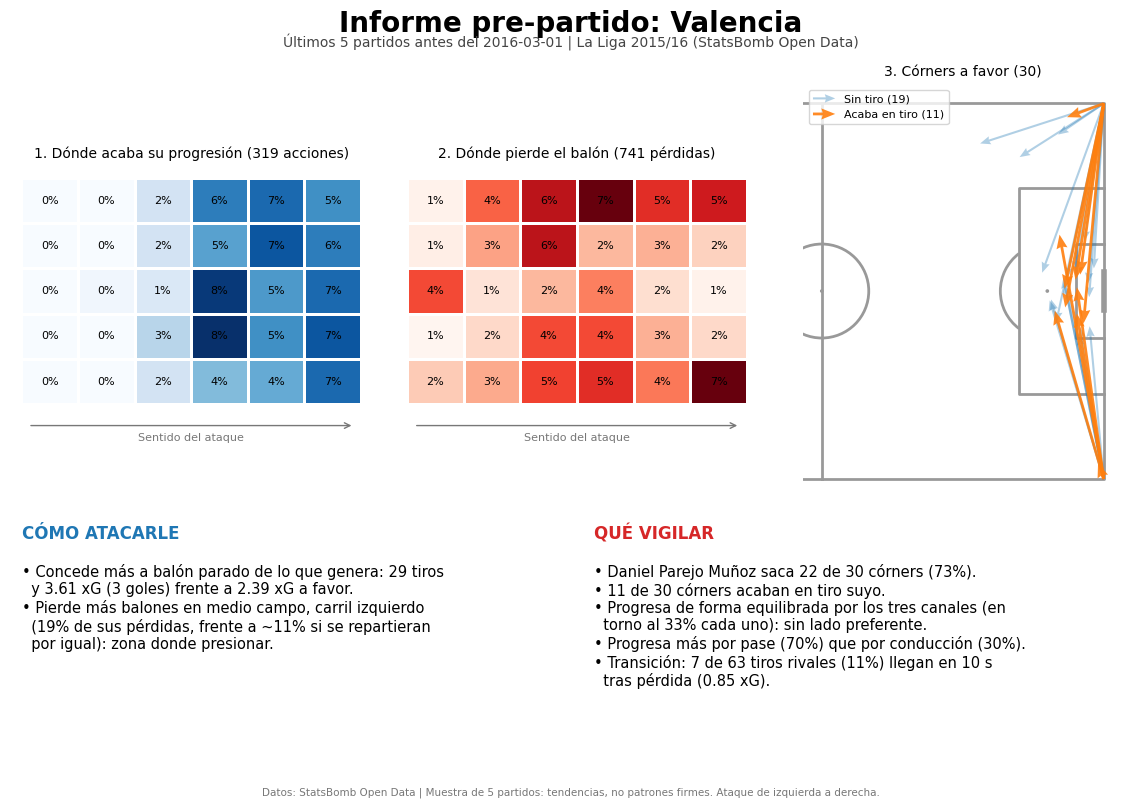

In [4]:
informe_rival("Valencia", "2016-03-01")